In [24]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import sqlite3
from sqlalchemy import create_engine, text

In [25]:
sns.set_style('ticks')
sns.set_style('whitegrid')

In [26]:
df_StoOrd = pd.read_csv("store_orders.csv")
df_StoCus = pd.read_csv("store_customers.csv")

In [27]:
df_StoOrd.head(10)

,order_id,customer_id,product,category,amount,order_date
0,5000,4,paper,office,14.09,2026-05-25
1,5001,15,planner,office,51.86,2026-05-08
2,5002,34,shelf,furniture,116.25,2026-06-03
3,5003,2,granola,snacks,19.72,2026-05-19
4,5004,17,monitor,electronics,284.80,2026-05-10
5,5005,16,monitor,electronics,66.10,2026-06-10
6,5006,27,headset,electronics,86.67,2026-06-08
7,5007,36,dock,electronics,103.77,2026-05-21
8,5008,30,headset,electronics,267.39,2026-06-08
9,5009,14,chair,furniture,107.20,2026-05-24


In [28]:
df_StoCus.head(10)

,customer_id,name,city,signup_year
0,1,Ana Lopez,Venice,2021
1,2,Ben Kim,Culver City,2023
2,3,Chloe Nguyen,Santa Monica,2021
3,4,Dev Patel,Los Angeles,2026
4,5,Elena Garcia,Culver City,2022
5,6,Farid Okafor,Culver City,2024
6,7,Grace Silva,Culver City,2025
7,8,Hugo Chen,Culver City,2023
8,9,Iris Ali,Inglewood,2026
9,10,Jon Brooks,Santa Monica,2021


data analysis - Imported Datasets (store_orders.csv & store_customers.csv)
----------------------------------
The datasets do look to be clean structured raw data. There are no missing values denoted as NA. There is no need to remmove any data points. The raw data needs to be cleaned.

In [29]:
db = create_engine("sqlite:///store.db")

In [30]:
conn = sqlite3.connect("store.db")
cur = conn.cursor()

# df_StoOrd.to_sql("orders", db, index=False)
# df_StoCus.to_sql("customers", db, index=False)

Once the tables were created, I had to comment out the code above to prevent an error.

In [31]:
pd.read_sql("SELECT * FROM orders LIMIT 10", db)

,order_id,customer_id,product,category,amount,order_date
0,5000,4,paper,office,14.09,2026-05-25
1,5001,15,planner,office,51.86,2026-05-08
2,5002,34,shelf,furniture,116.25,2026-06-03
3,5003,2,granola,snacks,19.72,2026-05-19
4,5004,17,monitor,electronics,284.80,2026-05-10
5,5005,16,monitor,electronics,66.10,2026-06-10
6,5006,27,headset,electronics,86.67,2026-06-08
7,5007,36,dock,electronics,103.77,2026-05-21
8,5008,30,headset,electronics,267.39,2026-06-08
9,5009,14,chair,furniture,107.20,2026-05-24


In [32]:
pd.read_sql("SELECT * FROM customers LIMIT 10", db)

,customer_id,name,city,signup_year
0,1,Ana Lopez,Venice,2021
1,2,Ben Kim,Culver City,2023
2,3,Chloe Nguyen,Santa Monica,2021
3,4,Dev Patel,Los Angeles,2026
4,5,Elena Garcia,Culver City,2022
5,6,Farid Okafor,Culver City,2024
6,7,Grace Silva,Culver City,2025
7,8,Hugo Chen,Culver City,2023
8,9,Iris Ali,Inglewood,2026
9,10,Jon Brooks,Santa Monica,2021


Setting Up the Established Query Pattern
================
Query the first 5 rows of orders

In [33]:
pd.read_sql("SELECT * FROM orders LIMIT 5", db)

,order_id,customer_id,product,category,amount,order_date
0,5000,4,paper,office,14.09,2026-05-25
1,5001,15,planner,office,51.86,2026-05-08
2,5002,34,shelf,furniture,116.25,2026-06-03
3,5003,2,granola,snacks,19.72,2026-05-19
4,5004,17,monitor,electronics,284.80,2026-05-10


Setting Up the Established Query Pattern
================
Write one query returning all orders over 100 dollars, sorted by amount from highest to lowest

In [34]:
query = """
SELECT amount
FROM orders
WHERE amount > 100
ORDER BY amount DESC;
"""

df_result = pd.read_sql(query, db)

display(df_result)

,amount
0,499.00
1,295.36
2,293.79
3,293.35
4,287.83
...,...
79,110.31
80,108.47
81,107.20
82,103.77


Output from Query as Expected

One query: for each product category, the number of orders and the average amount, named with AS, sorted by average amount descending 

In markdown, one sentence: which category earns the most per order?

In [37]:
query = """
SELECT category,
       COUNT(*) AS n,
       AVG(amount) AS avg_amount
FROM orders
GROUP BY category
ORDER BY avg_amount DESC;
"""

df_catCntAvg = pd.read_sql(query, db)

display(df_catCntAvg)

,category,n,avg_amount
0,electronics,60,190.569500
1,furniture,46,146.251522
2,office,51,30.132549
3,snacks,43,14.619767


Table Output Displayed as Expected - which category earns the most per order? electronics

Write the JOIN (Tutorial 5 pattern): total spend per customer city, using the key the data dictionary gives you, sorted by total descending.

Hint: SUM of the order amount, grouped by the customers table’s city column.

A JOIN matches rows across tables using a shared key column. Give each table a short alias, and always state the ON condition; forgetting it multiplies every row by every row. After any join, compare row counts to the original tables and explain differences (unmatched rows drop out of an inner join):
----------------

Using the .shape() function before the JOIN to get tables' original dimensions

In [38]:
df_StoOrd.shape

(200, 6)

In [39]:
df_StoCus.shape

(40, 4)

Performing the JOIN Query

In [57]:
query ="""
SELECT  c.name, 
        o.order_id,
        SUM(o.amount) AS total_amt,
        c.city
FROM customers AS c
JOIN orders AS o ON c.customer_id = o.customer_id 
GROUP BY city
ORDER BY total_amt DESC;

"""
df_tablesJOIN = pd.read_sql(query, db)

display(df_tablesJOIN)


,name,order_id,total_amt,city
0,Dev Patel,5000,5862.99,Los Angeles
1,Ben Kim,5003,5316.88,Culver City
2,Chloe Nguyen,5010,4017.93,Santa Monica
3,Iris Ali,5023,2718.25,Inglewood
4,Rosa Chen,5026,1037.25,Torrance
5,Ana Lopez,5068,462.36,Venice


Step 7
============

bar-chart total spend by city, fully labeled with title and units.

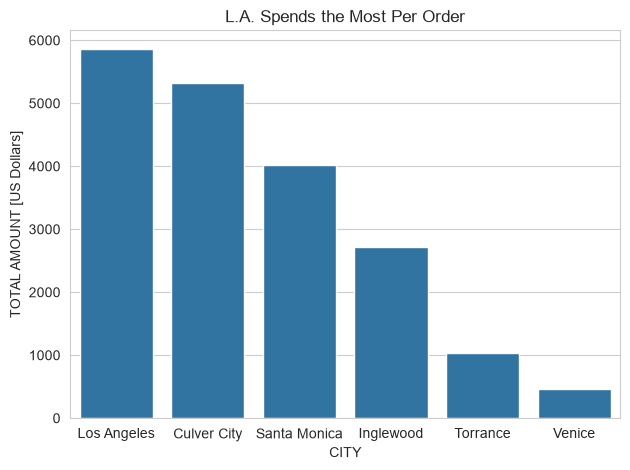

<Figure size 960x720 with 0 Axes>

In [59]:
sns.barplot(x='city', y='total_amt', data=df_tablesJOIN)
plt.title('L.A. Spends the Most Per Order')
plt.xlabel("CITY")
plt.ylabel("TOTAL AMOUNT [US Dollars]")
plt.tight_layout()
plt.figure(dpi=150.0)
plt.savefig('LA_MostPerOrder.png')
plt.show()

In [55]:
df_tablesJOIN.shape

(6, 4)

Count the rows of orders and the rows your join produced (before grouping, or by summing order counts per city).Count the rows of orders and the rows your join produced (before grouping, or by summing order counts per city) 

Step 6
========
rows of orders = 200, the rows my JOIN produced = 6. There were only 6 customers who placed orders. a JOIN combines data from two or more tables using a related column. In this case the related columns are primary & foreign keys that link the tables. Since both rows have to be commpon in both tables, it is evident that this represents an intersection of data.